##  Subramaniam 2013 — Leu codon sensitivity



In [2]:
include("packages.jl")
# packages.jl already includes functions.jl — do NOT include functions.jl again
println("call_model defined? ", isdefined(Main, :call_model))

🔧 Julia started with 12 threads
call_model defined? true


In [3]:
# ════════════════════════════════════════════════════════════════════════════
#  Subramaniam 2013 — Leu codon sensitivity, single gene, Spindler scale=1.
#  v5: (a) RIB-divergence retry restored (atol 1e-6, triggered on RIB>RIB_MAX only);
#      (b) third reporter C1A = yfp0 with ONE Leu site → CTA (titratable);
#      (c) t_end left at default 100; relative-time drift (te vs te-20).
# ════════════════════════════════════════════════════════════════════════════
using CSV, DataFrames, Statistics, Printf, Plots
include("goodman_2013.jl")

# ── knobs ───────────────────────────────────────────────────────────────────
prim       = "rplL"
LEU_IDX    = 10
LEU_LEVELS = [1.0, 0.3, 0.1, 0.05, 0.02]
m_reporter = 1.0
base_fasta = "Ecoli_K12_MG1655_geneset_with_welch_2009.fa"
pnas_fasta = joinpath("data","PNAS_2013","sd02.txt")
out_subdir = "pnas_leu_single_v5"
timeout_s  = 1800
ATOL0, ATOL_RETRY = 1e-4, 1e-6
RIB_MAX    = 100.0
SS_TOL     = 0.15

# ── reporters: yfp0 (CTG), yfp1 (7×CTA), and C1A = yfp0 with ONE site → CTA ──
recs = read_fasta_ordered(pnas_fasta)
getrec(p) = last(recs[findfirst(r -> startswith(first(r), p), recs)])
yfp0, yfp1 = getrec("yfp0"), getrec("yfp1")
cods0 = [yfp0[i:i+2] for i in 1:3:length(yfp0)]
cods1 = [yfp1[i:i+2] for i in 1:3:length(yfp1)]
sens_pos = findall(k -> cods0[k] != cods1[k], eachindex(cods0))
one_site = sens_pos[1]
cods_1 = copy(cods0); cods_1[one_site] = "CTA"
yfp_1cta = join(cods_1)
@printf("substituted sites: %s | single-CTA site for C1A: %d\n", string(sens_pos), one_site)

# (prefix, seq, linestyle, marker, cta_sites)
reporters = [
    ("CTG", yfp0,     :dash,  :square,  Int[]),
    ("C1A", yfp_1cta, :dot,   :diamond, [one_site]),
    ("CTA", yfp1,     :solid, :circle,  sens_pos),
]

mk_scale(la) = (ars = ones(20); ars[LEU_IDX] = la; txtl_types.make_scale(
    V_TC_scale=1.0, k_TLEmaxj_scale=1.0, V_IN_70SIC_scale=1.0, V_IN_IF2D_scale=1.0,
    Rib_scale=1.0, IF_scale=1.0, EF_scale=1.0, tRNA_scale=1.0,
    ARS_scale=ars, RibRecycling=0.0, V_mDeg_scale=0.0))

base_records = read_fasta_ordered(joinpath("..","data","sequences", base_fasta))
het_conc = Dict(prim => m_reporter)

function _run(f, ts)
    ch = Channel{Any}(1)
    t  = @async try; put!(ch,(:ok,f())); catch e; put!(ch,(:error,e)); end
    t0 = time(); while !istaskdone(t); time()-t0>ts && return (:timeout,nothing,time()-t0); sleep(0.5); end
    s,p = take!(ch); return (s,p,time()-t0)
end

function decode_pools(payload, gene, te)
    p = payload.p; si = _find_seq_index(p, gene); tg = p.local_tags_list[si]
    us = extract_u_sequence(payload.sol(te), p, si); ns = tg.num_species
    cC = tg.t3_Codon_struc * reshape(max.(us[1:ns], 0.0), 1, ns)'
    ci = tg.species_and_sequences.cod_idx
    poolof(target) = begin
        for (k, v) in ci; string(k) == target && return cC[v]; end
        return NaN
    end
    return (cta = poolof("CUA"), ctg = poolof("CUG"))
end

profiles = Dict{String,Any}(); rows = NamedTuple[]
mkpath(joinpath("..","data","sequences",out_subdir)); mkpath("../data/output/figures")

function one_solve(cds, la, atol, rel)
    write_fasta_with_replacement(base_records, prim, cds, joinpath("..","data","sequences",rel))
    _run(timeout_s) do
        call_model(rel, [prim], 0; custom_scale=mk_scale(la), growth_rate=1, het_mRNA_conc=het_conc,
            return_details=true, return_sol=true, static_EFs=true, spindler_75pct=false,
            ode_reltol=1e-8, ode_abstol=atol, ode_maxiters=5_000_000)
    end
end

function eval_metrics(payload)
    te     = float(payload.sol.t[end])
    spEnd  = spindler_codon_translation_time(payload.sol, payload.p, prim; t_sample = te)
    spPrev = spindler_codon_translation_time(payload.sol, payload.p, prim; t_sample = max(te - 20, payload.sol.t[1]))
    dg     = collect_pool_diagnostics(payload.sol, payload.p, te; primary_gene=prim)
    dp     = decode_pools(payload, prim, te)
    drift  = abs(spEnd.total_time_s - spPrev.total_time_s) / max(spEnd.total_time_s, 1e-9)
    (te=te, sp=spEnd, dg=dg, dp=dp, drift=drift)
end

function run_case(label, cds, la, cta_sites, ls)
    rel = joinpath(out_subdir, replace(label, r"[^A-Za-z0-9_]"=>"_") * ".fa")
    @printf("\n%-12s (Leu-ARS=%.3g) ", label, la); flush(stdout)
    atol = ATOL0
    status, payload, _ = one_solve(cds, la, atol, rel)
    ok = status==:ok && payload!==nothing && successful_retcode(payload.sol)
    m  = ok ? eval_metrics(payload) : nothing
    if ok && m.dg.RIB_active > RIB_MAX                 # retry ONLY for numerical RIB blow-up
        @printf("[retry %.0e: RIB=%.0f] ", ATOL_RETRY, m.dg.RIB_active); flush(stdout)
        atol = ATOL_RETRY
        status, payload, _ = one_solve(cds, la, atol, rel)
        ok = status==:ok && payload!==nothing && successful_retcode(payload.sol)
        m  = ok ? eval_metrics(payload) : nothing
    end
    if ok
        stationary = (m.te >= 100-1e-9) && (m.dg.RIB_active <= RIB_MAX) && (m.drift <= SS_TOL)
        win = filter(p -> p <= m.sp.L, sens_pos)
        cs  = filter(p -> p <= m.sp.L, cta_sites)
        profiles[label] = (tau=m.sp.tau, v=m.sp.v_smooth, stationary=stationary, ls=ls)
        r = (label=label, leu_ars=la, stationary=stationary, stot=m.sp.total_time_s,
             win_tau=sum(m.sp.tau[win]), cta_tau = isempty(cs) ? 0.0 : sum(m.sp.tau[cs]),
             mean_v=m.sp.mean_v, PRT=m.dg.PRT_primary, RIB=m.dg.RIB_active,
             cta_pool=m.dp.cta, ctg_pool=m.dp.ctg, drift=m.drift, atol=atol)
        @printf("%s Στ=%.2f winτ=%.2f ctaτ=%.2f PRT=%.3f RIB=%.1f CTApool=%.3g drift=%d%%",
                stationary ? "ok   " : "jam? ", r.stot, r.win_tau, r.cta_tau, r.PRT, r.RIB, r.cta_pool, round(Int,100r.drift))
    else
        r = (label=label, leu_ars=la, stationary=false, stot=NaN, win_tau=NaN, cta_tau=NaN,
             mean_v=NaN, PRT=NaN, RIB=NaN, cta_pool=NaN, ctg_pool=NaN, drift=NaN, atol=atol)
        @printf("FAILED (%s)", status)
    end
    push!(rows, r); return r
end

for la in LEU_LEVELS, (rep, seq, ls, mk, cs) in reporters
    run_case(@sprintf("%s_%.3g", rep, la), seq, la, cs, ls)
end
res = DataFrame(rows); CSV.write("../data/output/pnas_leu_single_v5.csv", res)
println("\n\nSaved → ../data/output/pnas_leu_single_v5.csv"); show(res, allcols=true); println()

# ── gate: C1A should now show a GRADED CTApool fall (1 CTA ≠ instant exhaustion)
println("\nGate — CTA decoding pool vs Leu-ARS (C1A = titratable, CTA = saturated):")
for rep in ("C1A","CTA")
    for r in eachrow(sort(filter(x->startswith(x.label,rep), res), :leu_ars, rev=true))
        @printf("  %-3s Leu-ARS=%.3g  CTApool=%.3g  ctaτ=%.3g  stationary=%s\n",
                rep, r.leu_ars, r.cta_pool, r.cta_tau, r.stationary)
    end
end

# ── plots: τ and v profiles (all successful; non-stationary dimmed) ──────────
pal = Dict(1.0=>:seagreen, 0.3=>:gold, 0.1=>:orange, 0.05=>:tomato, 0.02=>:firebrick)
function prof(field, ylab, title)
    plt = plot(xlabel="codon position", ylabel=ylab, title=title, legend=:topright, size=(950,420))
    for p in sens_pos; vline!(plt, [p], c=:gray, alpha=0.2, label=false); end
    for la in LEU_LEVELS, (rep, seq, ls, mk, cs) in reporters
        k = @sprintf("%s_%.3g", rep, la); haskey(profiles,k) || continue
        y = getproperty(profiles[k], field)
        al = profiles[k].stationary ? 1.0 : 0.4
        plot!(plt, 1:length(y), y, lw=1.6, ls=ls, c=get(pal,la,:black), alpha=al,
              label=@sprintf("%s ARS=%.3g", rep, la))
    end
    plt
end
pA = prof(:tau, "τ (s/codon)", "Per-codon dwell (dim=non-stationary; gray=sites)")
pB = prof(:v,   "v_smooth (codons/s)", "Smoothed elongation rate")

# ── titration: PRT and CTA-pool vs Leu-ARS, per reporter ─────────────────────
succ = filter(x->isfinite(x.PRT), res)
pP = plot(xlabel="Leu-ARS", ylabel="PRT (µM)", title="Protein output", xscale=:log10, legend=:bottomright)
pQ = plot(xlabel="Leu-ARS", ylabel="CTA decoding pool (µM)", title="CTA-reader pool", xscale=:log10, legend=:topleft)
for (rep, seq, ls, mk, cs) in reporters
    d = sort(filter(x->startswith(x.label,rep), succ), :leu_ars)
    nrow(d)==0 && continue
    plot!(pP, d.leu_ars, d.PRT, m=mk, label=rep)
    plot!(pQ, d.leu_ars, d.cta_pool, m=mk, label=rep)
end
pC = plot(pP, pQ, layout=(1,2), size=(1000,400))

savefig(pA, "../data/output/figures/v5_dwell.png")
savefig(pB, "../data/output/figures/v5_velocity.png")
savefig(pC, "../data/output/figures/v5_summary.png")
println("Figures → ../data/output/figures/v5_{dwell,velocity,summary}.png")
#display(pA); display(pB); display(pC)

substituted sites: [42, 44, 46, 53, 60, 64, 68] | single-CTA site for C1A: 42

CTG_1        (Leu-ARS=1) Number of sequences: 1 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605671156839 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248346427697   [~5–9]
  Est/S50      = 0.9684241303541532   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003845920608   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF  rtol=1.0e-8  atol=0.0001  maxiters=5000000  (n_seq=1)
Integration completed!
jam?  Στ=17.46 winτ=0.54 ctaτ=0.00 PRT=1.746 RIB=20.1 CTApool=0.3

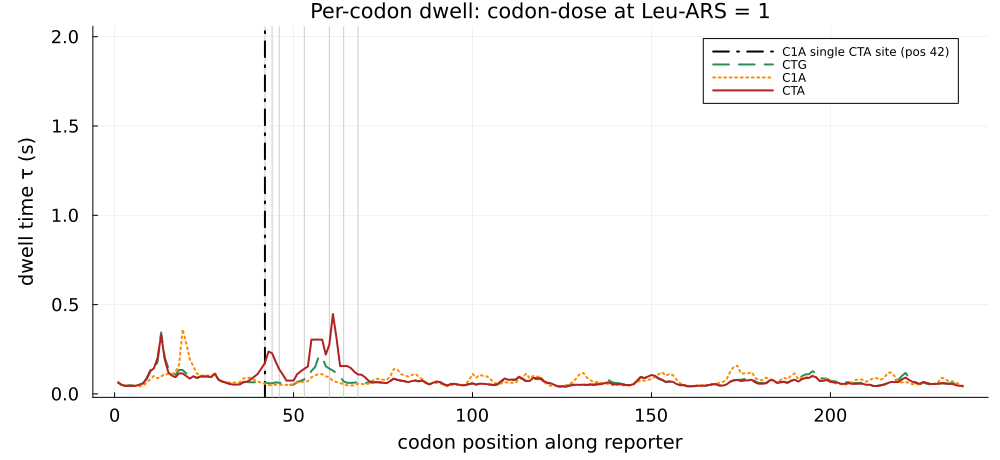

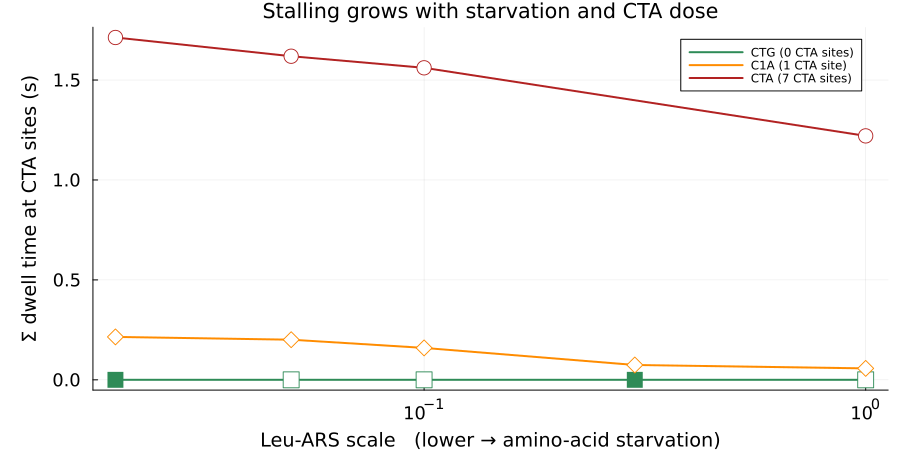

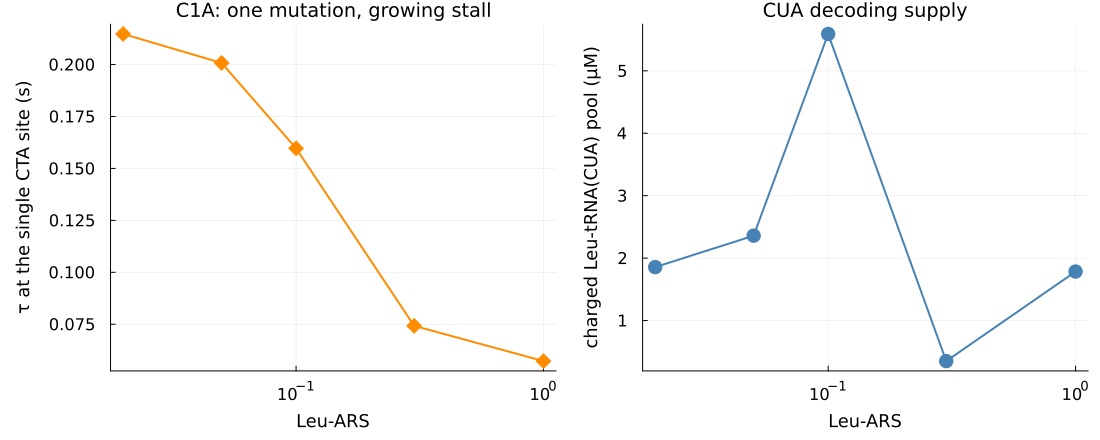

Saved result4a/b/c → ../data/output/figures/


In [4]:
using Plots, Printf, CSV, DataFrames
gr()
isdefined(Main, :res) || (res = CSV.read("../data/output/pnas_leu_single_v5.csv", DataFrame))

repcol = Dict("CTG"=>:seagreen, "C1A"=>:darkorange, "CTA"=>:firebrick)
repls  = Dict("CTG"=>:dash,     "C1A"=>:dot,        "CTA"=>:solid)
repmk  = Dict("CTG"=>:square,   "C1A"=>:diamond,    "CTA"=>:circle)
nsite  = Dict("CTG"=>0, "C1A"=>1, "CTA"=>7)

# filled = stationary/converged, open = jam/non-stationary
function add_series!(plt, rep, ycol)
    d = sort(filter(r -> startswith(r.label, rep) && isfinite(getproperty(r, ycol)), res), :leu_ars)
    nrow(d) == 0 && return
    x = d.leu_ars; y = getproperty(d, ycol); st = d.stationary
    plot!(plt, x, y; lw = 2, c = repcol[rep],
          label = @sprintf("%s (%d CTA site%s)", rep, nsite[rep], nsite[rep] == 1 ? "" : "s"))
    any(st)    && scatter!(plt, x[st],    y[st];    m = repmk[rep], ms = 8, c = repcol[rep], msc = repcol[rep], label = "")
    any(.!st)  && scatter!(plt, x[.!st],  y[.!st];  m = repmk[rep], ms = 8, mc = :white,      msc = repcol[rep], label = "")
end

# ── (a) spatial stall signature: 0 vs 1 vs 7 CTA sites, clean baseline ──
ARS_SHOW = 1.0
pa = plot(size = (1000, 460), legend = :topright,
          xlabel = "codon position along reporter", ylabel = "dwell time τ (s)",
          title = @sprintf("Per-codon dwell: codon-dose at Leu-ARS = %.2g", ARS_SHOW),
          titlefontsize = 14, guidefontsize = 13, tickfontsize = 12,
          left_margin = 8Plots.mm, bottom_margin = 6Plots.mm)
for p in sens_pos; vline!(pa, [p]; c = :gray80, lw = 1, label = ""); end
vline!(pa, [one_site]; c = :black, lw = 2, ls = :dashdot, label = "C1A single CTA site (pos $one_site)")
for rep in ("CTG", "C1A", "CTA")
    k = @sprintf("%s_%.3g", rep, ARS_SHOW)
    haskey(profiles, k) && plot!(pa, 1:length(profiles[k].tau), profiles[k].tau;
                                 lw = 2, c = repcol[rep], ls = repls[rep], label = rep)
end

# ── (b) starvation titration: dwell at CTA sites vs ARS, by codon dose ──
pb = plot(size = (900, 460), xscale = :log10, legend = :topright,
          xlabel = "Leu-ARS scale   (lower → amino-acid starvation)",
          ylabel = "Σ dwell time at CTA sites (s)",
          title = "Stalling grows with starvation and CTA dose",
          titlefontsize = 14, guidefontsize = 13, tickfontsize = 12,
          left_margin = 8Plots.mm, bottom_margin = 6Plots.mm)
for rep in ("CTG", "C1A", "CTA"); add_series!(pb, rep, :cta_tau); end

# ── (c) the single-mutation experiment: C1A site dwell vs its charged-tRNA pool ──
d1  = sort(filter(r -> startswith(r.label, "C1A"), res), :leu_ars)
pc1 = plot(d1.leu_ars, d1.cta_tau; xscale = :log10, m = :diamond, ms = 8, lw = 2,
           c = :darkorange, msc = :darkorange, legend = false,
           xlabel = "Leu-ARS", ylabel = "τ at the single CTA site (s)",
           title = "C1A: one mutation, growing stall",
           titlefontsize = 13, guidefontsize = 12, tickfontsize = 11)
pc2 = plot(d1.leu_ars, d1.cta_pool; xscale = :log10, m = :circle, ms = 8, lw = 2,
           c = :steelblue, msc = :steelblue, legend = false,
           xlabel = "Leu-ARS", ylabel = "charged Leu-tRNA(CUA) pool (µM)",
           title = "CUA decoding supply",
           titlefontsize = 13, guidefontsize = 12, tickfontsize = 11)
pc = plot(pc1, pc2; layout = (1, 2), size = (1100, 440),
          left_margin = 8Plots.mm, bottom_margin = 8Plots.mm)

mkpath("../data/output/figures")
savefig(pa, "../data/output/figures/result4a_dwell_profile.png")
savefig(pb, "../data/output/figures/result4b_cta_titration.png")
savefig(pc, "../data/output/figures/result4c_C1A_single_site.png")
println("Saved result4a/b/c → ../data/output/figures/")
display(pa); display(pb); display(pc)